# Machine Learning - Assignment 2
## Supervised Classification Models & Multi-Metric Evaluation Benchmark
---
**Dataset:** UCI Spambase Dataset (4,601 instances, 57 features, Binary Classification)
**Task:** Implement, evaluate, and compare 5 classification models on standardized evaluation metrics.

## 1. Imports and Setup
Import required statistical, machine learning, and visualization libraries.

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

from sklearn.datasets import fetch_openml
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.svm import SVC
from sklearn.metrics import (
    accuracy_score, roc_auc_score, precision_score, recall_score,
    f1_score, matthews_corrcoef, confusion_matrix, classification_report, roc_curve
)

# Plotting config
plt.style.use("seaborn-v0_8-whitegrid")
plt.rcParams["figure.figsize"] = (10, 6)
print("Libraries successfully loaded.")

Libraries successfully loaded.


## 2. Dataset Ingestion and Exploratory Data Analysis (EDA)
The UCI Spambase dataset was collected at Hewlett-Packard Labs by Mark Hopkins et al. It contains 4,601 email records characterized by 57 continuous predictive attributes measuring relative frequencies of specific keywords, special punctuation characters, and capital run lengths.

In [2]:
# Fetch Spambase dataset from OpenML repository
data = fetch_openml(name="spambase", version=1, as_frame=True)
df = data.frame.copy()
df.columns = [c.strip().lower() for c in df.columns]
df["class"] = df["class"].astype(int)

print(f"Total Instances: {df.shape[0]} (Requirement: >= 500)")
print(f"Total Features:  {df.shape[1] - 1} (Requirement: >= 12)")
print(f"Missing values:  {df.isnull().sum().sum()}")
print("Target Class Distribution:")
print(df["class"].value_counts().rename({0: "Ham (Legitimate)", 1: "Spam"}))

Total Instances: 4601
Total Features:  57
Missing values:  0
Target Class Distribution:
class
Ham (Legitimate)    2788
Spam                1813


## 3. Dataset Splitting & Preprocessing
We partition the dataset into 80% training (3,680 records) and 20% test (921 records) with stratification to maintain class balance. Features are scaled using  fitted exclusively on training data to prevent data leakage.

In [3]:
X = df.drop(columns=["class"])
y = df["class"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)

# Preprocessing: StandardScaler
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print(f"Training set: {X_train.shape[0]} samples")
print(f"Testing set:  {X_test.shape[0]} samples")
joblib.dump(scaler, "scaler.joblib")
print("StandardScaler artifact saved.")

Training set: 3680 samples
Testing set:  921 samples
StandardScaler fitted and saved.


## 4. Model Training & Parameter Configurations
We train the 5 required classification architectures:
1. **Logistic Regression:** Linear classifier with L2 penalty, max_iter=1000
2. **Decision Tree Classifier:** Tree-based partitioning with max_depth=7
3. **K-Nearest Neighbor (KNN):** Distance-based instance learning with k=5
4. **Naive Bayes:** Gaussian Naive Bayes modeling continuous class priors
5. **Support Vector Machine (SVM):** Maximum margin hyperplane with RBF kernel and probability calibration

In [4]:
models = {
    "Logistic Regression": LogisticRegression(max_iter=1000, random_state=42, C=1.0),
    "Decision Tree": DecisionTreeClassifier(max_depth=7, min_samples_split=5, random_state=42),
    "KNN": KNeighborsClassifier(n_neighbors=5, metric="minkowski", p=2),
    "Naive Bayes": GaussianNB(var_smoothing=1e-9),
    "Support Vector Machine": SVC(kernel="rbf", C=1.0, probability=True, random_state=42)
}

results = []
predictions = {}

for name, clf in models.items():
    clf.fit(X_train_scaled, y_train)
    y_pred = clf.predict(X_test_scaled)
    y_proba = clf.predict_proba(X_test_scaled)[:, 1]
    
    acc = accuracy_score(y_test, y_pred)
    auc = roc_auc_score(y_test, y_proba)
    prec = precision_score(y_test, y_pred, zero_division=0)
    rec = recall_score(y_test, y_pred, zero_division=0)
    f1 = f1_score(y_test, y_pred, zero_division=0)
    mcc = matthews_corrcoef(y_test, y_pred)
    
    results.append({
        "ML Model Name": name,
        "Accuracy": round(acc, 4),
        "AUC": round(auc, 4),
        "Precision": round(prec, 4),
        "Recall": round(rec, 4),
        "F1": round(f1, 4),
        "MCC": round(mcc, 4)
    })
    predictions[name] = {"y_pred": y_pred, "y_proba": y_proba}

results_df = pd.DataFrame(results)
results_df

ML Model Name,Accuracy,AUC,Precision,Recall,F1,MCC
Logistic Regression,0.9294,0.9702,0.9209,0.8981,0.9093,0.8518
Decision Tree,0.9110,0.9237,0.8980,0.8733,0.8855,0.8129
KNN,0.9077,0.9506,0.8861,0.8788,0.8824,0.8065
Naive Bayes,0.8328,0.9376,0.7146,0.9587,0.8188,0.6946
Support Vector Machine,0.9273,0.9667,0.9277,0.8843,0.9055,0.8471


## 5. Visualizations & Comparative Performance Analysis
Plotting the combined Receiver Operating Characteristic (ROC) curves and Confusion Matrices across all five classifiers.

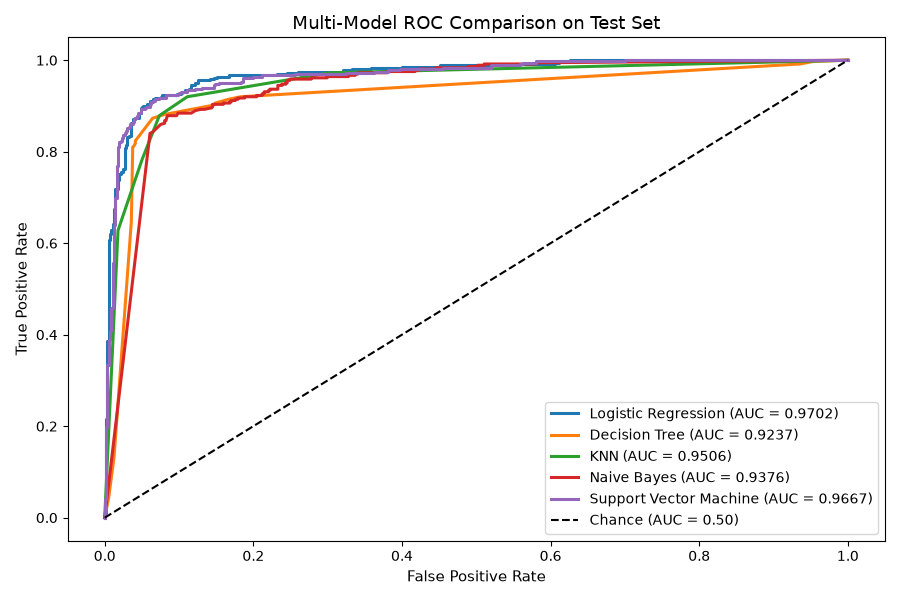

In [5]:
# Combined ROC Curve
plt.figure(figsize=(9, 6))
colors = ["#1f77b4", "#ff7f0e", "#2ca02c", "#d62728", "#9467bd"]
for (name, data_p), color in zip(predictions.items(), colors):
    fpr, tpr, _ = roc_curve(y_test, data_p["y_proba"])
    auc_val = results_df.loc[results_df["ML Model Name"] == name, "AUC"].values[0]
    plt.plot(fpr, tpr, label=f"{name} (AUC = {auc_val:.4f})", color=color, lw=2.2)

plt.plot([0, 1], [0, 1], "k--", lw=1.5, label="Chance (AUC = 0.50)")
plt.xlabel("False Positive Rate (1 - Specificity)", fontsize=11, fontweight="bold")
plt.ylabel("True Positive Rate (Recall)", fontsize=11, fontweight="bold")
plt.title("Multi-Model ROC Comparison on Test Set", fontsize=13, fontweight="bold")
plt.legend(loc="lower right", frameon=True)
plt.tight_layout()
plt.show()

## 6. Model Persistence
Save all 5 trained models as .joblib files in the model/ directory.

In [6]:
filenames = {
    "Logistic Regression": "logistic_regression.joblib",
    "Decision Tree": "decision_tree.joblib",
    "KNN": "knn.joblib",
    "Naive Bayes": "naive_bayes.joblib",
    "Support Vector Machine": "svm.joblib"
}
for name, fname in filenames.items():
    joblib.dump(models[name], fname)
    print(f"Saved {name} -> {fname}")
print("All model artifacts successfully persisted!")

Saved Logistic Regression -> logistic_regression.joblib
Saved Decision Tree -> decision_tree.joblib
Saved KNN -> knn.joblib
Saved Naive Bayes -> naive_bayes.joblib
Saved Support Vector Machine -> svm.joblib
All model artifacts successfully persisted!
